# Harry Ferguson - CIS 361 - Summer 2026 - Assignment 2

Number of tweets: 14640

airline_sentiment
negative    0.626913
neutral     0.211680
positive    0.161407
Name: proportion, dtype: float64

Accuracy: 0.6639344262295082

Classification Report:
              precision    recall  f1-score   support

    negative       0.65      1.00      0.79      1808
     neutral       0.86      0.11      0.20       636
    positive       0.93      0.14      0.24       484

    accuracy                           0.66      2928
   macro avg       0.81      0.42      0.41      2928
weighted avg       0.74      0.66      0.57      2928



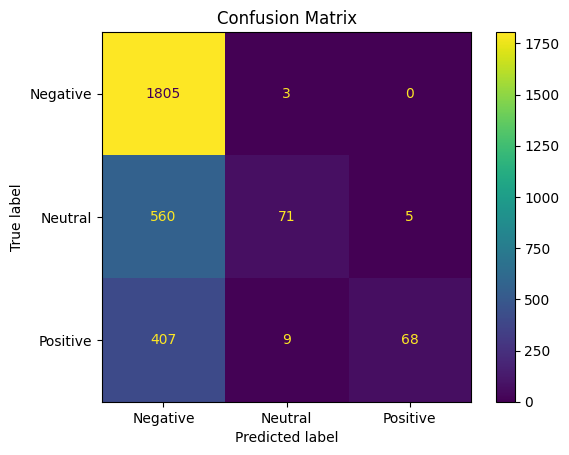

Predictions on test tweets:

I loved the flight: negative
I hated the flight: negative
The flight was OK: negative
The flight was too cold: negative
The flight was too long: negative
Waiting for takeoff was unbearable: negative
He will be there: negative
We had the best time: negative
Thank you: positive
Water is wet: negative
The customer service is lousy: negative
I want to reschedule my flight: negative
Flying the friendly skies: negative
American Airlines is better: negative
Good: negative


In [19]:
import nltk
import pandas
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
import random
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Read and prepare data
df = pandas.read_csv('Tweets/Tweets.csv')[['text', 'airline_sentiment']]
print(f"Number of tweets: {len(df)}\n")
print(df.value_counts(subset='airline_sentiment', normalize=True))

df['text'] = df['text'].str.lower()
tweets = list(df.to_records(index=False))

# Shuffle the documents
random.shuffle(tweets)

# Split the data into train and test sets
train_documents, test_documents = train_test_split(tweets, test_size=0.2, random_state=42)

# Split features and labels
X_train, y_train = zip(*train_documents)
X_test, y_test = zip(*test_documents)

# Convert text data into TF-IDF vectors
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

clf = MultinomialNB()
clf.fit(X_train_tfidf, y_train)

# Predict on test data
y_pred = clf.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

# Generate classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Generate confusion matrix
cm_labels = ('Negative', 'Neutral', 'Positive')
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cm_labels)
disp.plot()
plt.title('Confusion Matrix')
plt.show()

print("Predictions on test tweets:\n")
test_tweets = ('I loved the flight', 'I hated the flight', 'The flight was OK', 'The flight was too cold', 'The flight was too long', 
                  'Waiting for takeoff was unbearable', 'He will be there', 'We had the best time', 'Thank you', 'Water is wet', 'The customer service is lousy',
                  "I want to reschedule my flight", 'Flying the friendly skies', 'American Airlines is better', 'Good')

for test_tweet in test_tweets:
    print(f'{test_tweet}: {clf.predict(vectorizer.transform([test_tweet]))[0]}')


The csv file contained 14640 tweets, of which over 62% were classified as having a negative sentiment, 21% expressing a neutral sentiment, and only 16% with a positive sentiment. The Naive Bayes model trained on this data correctly predicted around 66% of the sentiments in the test data. Overall, the model seems to be biased towards finding negative sentiment. As can be seen from the recall score of 1 and from the confusion matrix, if the sentiment of a tweet is negative, the model correctly labeled it as such. However, the model frequently mislabeled positive and neutral sentiments as negative, as can be seen by the negative precision score of .65, the neutral and positive recall scores of 0.11 and 0.14 respectively, and the confusion matrix. By contrast, if the model labeled the tweet as positive or neutral, the label was usually correct. The bias toward negative sentiment can further be seen from the test tweets, where only one test tweet was correctly labeled as not negative ("Thank you"). This bias is almost certainly caused by the preponderance of negative tweets in the original file; a file with a more balanced ratio of sentiments would probly make far more accurate predictions.

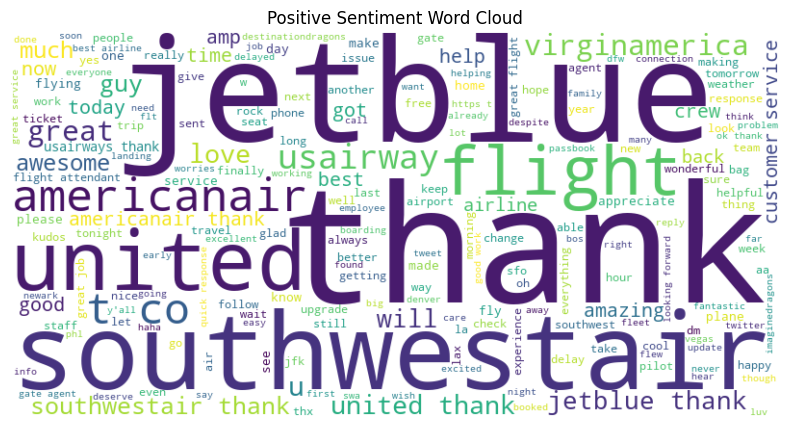

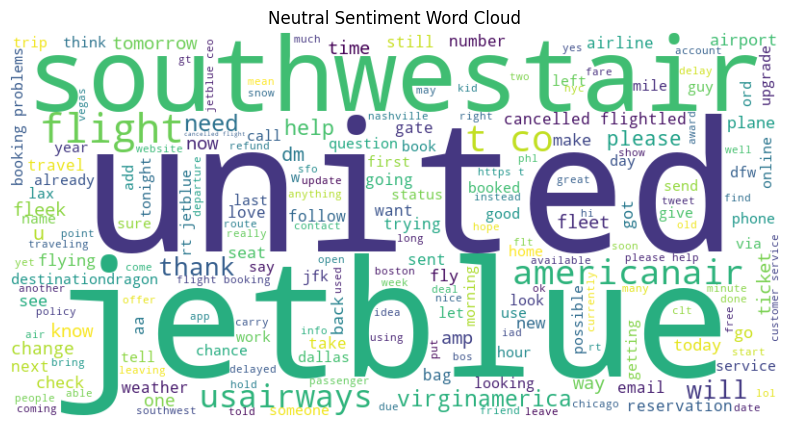

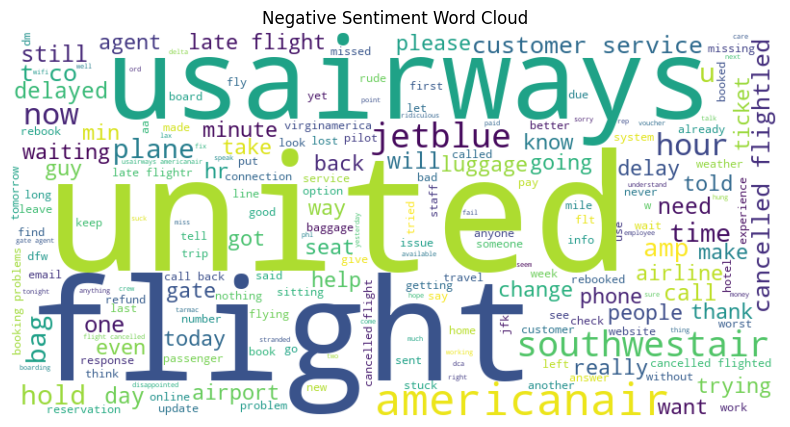

In [20]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from collections import defaultdict

# Create defaultdict to store words for each sentiment
sentiment_words = defaultdict(str)

# Iterate over text data and sentiment labels
for text, sentiment in tweets:
    # Tokenize the text (you may need to use more advanced preprocessing)
    words = text.split()
    # Aggregate words based on sentiment
    sentiment_words[sentiment] += " ".join(words) + " "

# Create WordCloud for each sentiment
for sentiment, words in sentiment_words.items():
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(words)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(sentiment.capitalize() + " Sentiment Word Cloud")
    plt.axis('off')
    plt.show()

The most interesting finding from the wordcloud analysis is which airlines are associated with each sentiment. JetBlue and Southwestern Airlines are strongly associated with postive and neutral sentiments. United Airlines is strongly associated with neutral or negative sentiments, while sentiments toward USAir is decidedly negative. American Airlines seems to be evenly distributed among all 3 sentiments, and there does not appear to any tweets regarding Delta. Finally, the prominence of "Thank" in the positive cloud probably explains why that test tweet was the only one correctly labeled as positive by the model.